# 06 — Spectral Analysis and Filtering

**Reference:** Shumway, R. H., & Stoffer, D. S. (2019). *Time Series: A Data Analysis Approach Using R*. Chapman & Hall/CRC Press.

## R setup

The examples use **base R** and the `astsa` package. The package provides the data and plotting/spectral functions `tsplot()`, `mvspec()`, and `arma.spec()`. Run the cells in order in an R runtime.

In [1]:
packages = c("astsa")
missing = packages[!sapply(packages, requireNamespace, quietly=TRUE)]
if (length(missing) > 0) install.packages(missing, repos="https://cloud.r-project.org")
library(astsa)
options(digits=5)
par(mfrow=c(1,1))

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



## 1. Frequency, period, amplitude, and phase

A **cycle** is one full repetition of an oscillation. **Frequency** $\omega$ is cycles per observation; **period** $T=1/\omega$ is observations per cycle. **Amplitude** $A$ is the maximum distance from the centerline. **Phase** $\phi$ shifts the oscillation along the time axis.

$$x_t=A\cos(2\pi\omega t+\phi).$$

Here $t$ is an observation index, $2\pi$ converts cycles into radians, $\omega$ sets the oscillation rate, and $\phi$ sets the starting position. A monthly series with $\omega=1/12$ has a 12-month period, while $\omega=1/48$ gives a 48-month period. A positive or negative phase changes *when* peaks occur, not how frequently.

Using the cosine addition identity:

$$x_t=U_1\cos(2\pi\omega t)+U_2\sin(2\pi\omega t),$$
$$U_1=A\cos\phi,\qquad U_2=-A\sin\phi.$$

If $U_1,U_2$ are uncorrelated, zero-mean random variables with equal variance $\sigma^2$, then the resulting process has mean zero and

$$\gamma(h)=\operatorname{Cov}(x_{t+h},x_t)=\sigma^2\cos(2\pi\omega h).$$

The covariance depends only on the **lag** $h$, giving weak stationarity under these assumptions. A fixed deterministic cosine alone should not be confused with a random process with this covariance.

Frequency: 0.083333 cycles per observation
Period: 12 observations per cycle
Amplitude: 2 ; phase: 1.885 radians


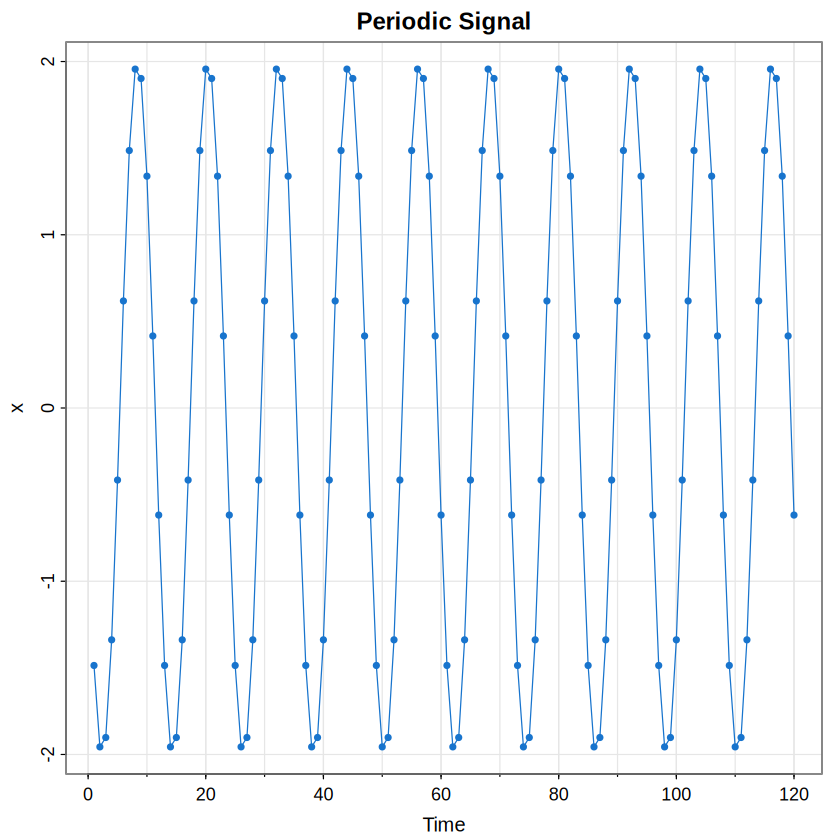

In [2]:
t = 1:120
omega = 1/12
A = 2
phi = .6*pi
x = A*cos(2*pi*omega*t + phi)

par(mfrow=c(1,1))
tsplot(x, type="o", col=4, pch=20, main="Periodic Signal", ylab="x")
cat("Frequency:", omega, "cycles per observation\n")
cat("Period:", 1/omega, "observations per cycle\n")
cat("Amplitude:", A, "; phase:", phi, "radians\n")

**Interpretation.** On the graph the horizontal axis counts observations; the vertical axis displays signal values. One cycle lasts 12 observations, so 120 observations contain 10 cycles. The vertical range is $[-2,2]$. The value $0.6\pi$ shifts the peaks relative to an unshifted cosine; it does not change their height or 12-observation spacing.

**Executed check:** The reported frequency is $0.083333$ cycle/observation and the period is $12$ observations, with amplitude $2$ and phase $1.885$ radians. The plotted cosine therefore completes ten cycles over the 120 observations; these values are fixed by the simulation parameters.

## 2. Sampling and aliasing

The **Nyquist (folding) frequency** for a discrete series is $1/2$ cycle per observation. With observations taken every $\Delta$ physical time units, it is $1/(2\Delta)$ cycles per physical time unit. **Aliasing** occurs when different continuous-time frequencies have identical sampled values; the apparent period can then differ from the actual period.

For a process with one cycle every 2 hours, sampling every 2.5 hours gives

$$f=\frac12\ \text{cycle/hour},\qquad f_s=\frac{1}{2.5}=0.4\ \text{sample/hour},$$
$$f_{\mathrm{alias}}=\left|f-f_s\right|=0.1\ \text{cycle/hour},\qquad T_{\mathrm{alias}}=10\ \text{hours}.$$

The true frequency exceeds the Nyquist limit $f_s/2=0.2$ cycle/hour. The alias calculation applies to this particular example; in general, aliases repeat at integer multiples of the sampling frequency.

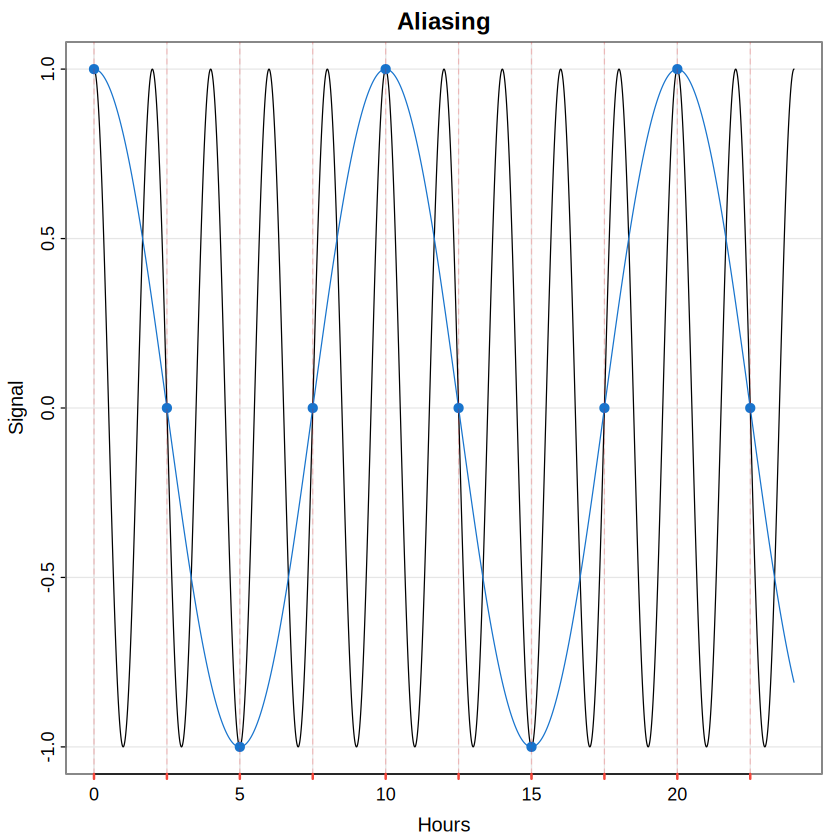

In [3]:
t = seq(0, 24, by=.01)
X = cos(2*pi*t*1/2)
tsplot(t, X, xlab="Hours", ylab="Signal", main="Aliasing")
T = seq(1, length(t), by=250)
points(t[T], X[T], pch=19, col=4)
lines(t, cos(2*pi*t/10), col=4)
axis(1, at=t[T], labels=FALSE, lwd.ticks=2, col.ticks=2)
abline(v=t[T], col=rgb(1,0,0,.2), lty=2)

**Graph interpretation.** The dense oscillation is the true 2-hour cosine. The blue dots are the readings 2.5 hours apart; they also lie on a much slower 10-hour cosine. From those sampled points alone, the rapid motion cannot be recovered uniquely. This is a sampling limitation, not measurement noise.

## 3. A mixture of three periodic components

A multi-frequency signal can be written as

$$x_t=\sum_{k=1}^{q}\left[a_k\cos(2\pi\omega_k t)+b_k\sin(2\pi\omega_k t)\right].$$

For component $k$, the **squared amplitude** is $A_k^2=a_k^2+b_k^2$ and the period is $T_k=1/\omega_k$. For the deterministic components below, $A_k^2$ quantifies the squared signal amplitude; the time variance of a complete centered sinusoid is $A_k^2/2$. This differs from the variance parameter $\sigma_k^2$ used when the sine/cosine coefficients are random with equal variance.

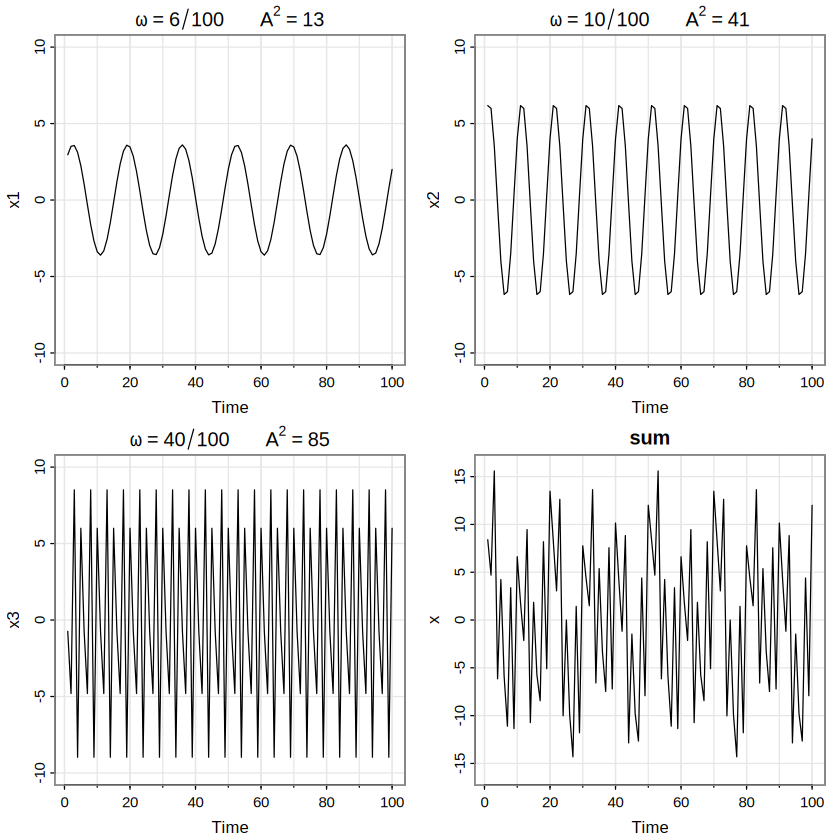

In [4]:
x1 = 2*cos(2*pi*1:100*6/100) + 3*sin(2*pi*1:100*6/100)
x2 = 4*cos(2*pi*1:100*10/100) + 5*sin(2*pi*1:100*10/100)
x3 = 6*cos(2*pi*1:100*40/100) + 7*sin(2*pi*1:100*40/100)
x = x1 + x2 + x3
par(mfrow=c(2,2))
tsplot(x1, ylim=c(-10,10), main=expression(omega==6/100~~~A^2==13))
tsplot(x2, ylim=c(-10,10), main=expression(omega==10/100~~~A^2==41))
tsplot(x3, ylim=c(-10,10), main=expression(omega==40/100~~~A^2==85))
tsplot(x, ylim=c(-16,16), main="sum")
par(mfrow=c(1,1))

In [5]:
frequency = c(6,10,40)/100
squared_amplitude = c(2^2+3^2, 4^2+5^2, 6^2+7^2)
results = data.frame(frequency=frequency, period=1/frequency,
                     amplitude=sqrt(squared_amplitude),
                     squared_amplitude=squared_amplitude)
print(results)
cat("Mean of combined signal:", mean(x), "\n")
cat("Population-variance-style mean squared deviation:", mean((x-mean(x))^2), "\n")
cat("Expected variance from complete orthogonal cycles:", sum(squared_amplitude)/2, "\n")

  frequency period amplitude squared_amplitude
1      0.06 16.667    3.6056                13
2      0.10 10.000    6.4031                41
3      0.40  2.500    9.2195                85
Mean of combined signal: -5.2671e-15 
Population-variance-style mean squared deviation: 69.5 
Expected variance from complete orthogonal cycles: 69.5 


**Interpretation.** The component frequencies are $0.06$, $0.10$, and $0.40$ cycles per observation; the periods are approximately $16.67$, $10$, and $2.5$ observations. Squared amplitudes are **13**, **41**, and **85**, respectively. The third component oscillates fastest and has the largest amplitude, so it creates strong rapid fluctuations in the sum. The first two provide slower variation.

These three frequencies are Fourier-grid frequencies ($j/100$), so their sampled cosine/sine components are orthogonal over 100 points. Consequently, their mean squared deviations add: $(13+41+85)/2=69.5$ (apart from floating-point rounding). The sample variance from `var(x)` uses a denominator of $n-1$, so it need not equal 69.5 exactly.

**Executed values:** The combined series mean is $-5.2671\times10^{-15}$, effectively zero, and its mean squared deviation is exactly $69.5$ to displayed precision. This agrees with $(13+41+85)/2$ and confirms the components are orthogonal on the sampled Fourier grid.

## 4. Fourier coefficients and the scaled periodogram

The **discrete Fourier transform (DFT)** describes the contributions of discrete frequency components. For observations $x_1,\ldots,x_n$ and Fourier frequencies $\omega_j=j/n$:

$$a_j=\frac{2}{n}\sum_{t=1}^n x_t\cos(2\pi tj/n),\qquad b_j=\frac{2}{n}\sum_{t=1}^n x_t\sin(2\pi tj/n),$$

$$d(\omega_j)=\frac1{\sqrt n}\sum_{t=1}^n x_t e^{-2\pi i tj/n},$$

$$I(\omega_j)=|d(\omega_j)|^2,\qquad P(\omega_j)=\frac4n I(\omega_j)=a_j^2+b_j^2.$$

Here $i^2=-1$, $|\cdot|$ means complex modulus, $I$ is the **periodogram**, and $P$ is the **scaled periodogram** used here. These equalities apply at nonzero, non-Nyquist Fourier frequencies; the zero-frequency and (for even $n$) Nyquist components have different normalizations. Large spectral peaks indicate strong frequency components. Peak size depends on the chosen normalization and does not automatically establish statistical significance.

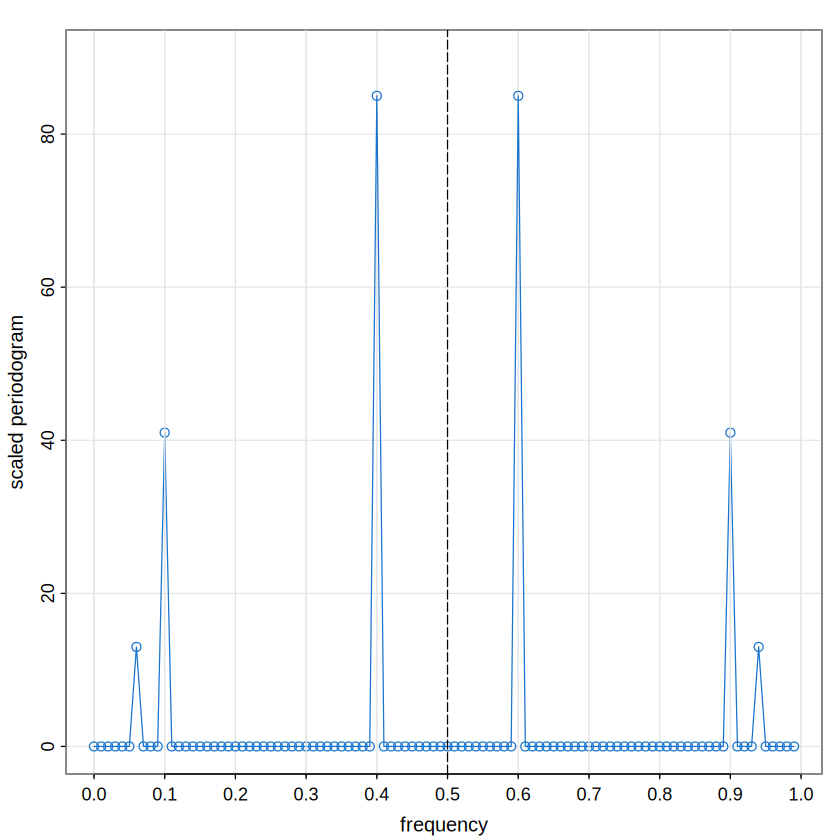

In [6]:
P = Mod(fft(x)/sqrt(100))^2  # periodogram
sP = (4/100)*P                # scaled periodogram
Fr = 0:99/100                 # fundamental frequencies
tsplot(Fr, sP, type="o", xlab="frequency", ylab="scaled periodogram",
       col=4, ylim=c(0,90))
abline(v=.5, lty=5)
abline(v=c(.1,.3,.7,.9), lty=1, col=gray(.9))
axis(side=1, at=seq(.1,.9,by=.2))

In [7]:
idx = c(6,10,40,60,90,94) + 1  # R indices start at one
spectral_peaks = data.frame(frequency=Fr[idx], scaled_power=sP[idx])
print(spectral_peaks)
cat("Maximum absolute difference from target squared amplitudes:",
    max(abs(sP[c(7,11,41)] - c(13,41,85))), "\n")
cat("Largest value away from the six peak bins:",
    max(sP[-idx]), "\n")

  frequency scaled_power
1      0.06           13
2      0.10           41
3      0.40           85
4      0.60           85
5      0.90           41
6      0.94           13
Maximum absolute difference from target squared amplitudes: 1.4211e-13 
Largest value away from the six peak bins: 1.0552e-27 


**Result and graph interpretation.** Peaks occur at $0.06$, $0.10$, and $0.40$ with heights **13**, **41**, and **85**. Mirror peaks appear at $0.94$, $0.90$, and $0.60$, because real-valued data give $P(\omega)=P(1-\omega)$ on this grid. Only $0\leq\omega\leq0.5$ is needed for a nonredundant display. The other bins are theoretically zero in this constructed example, subject to floating-point error. The value of a peak here is **squared amplitude**, not the conventional variance contribution.

**Numerical precision check:** The maximum discrepancy between the three measured peak heights and $13$, $41$, and $85$ is $1.4211\times 10^{-13}$. The largest nonpeak ordinate is only $1.0552\times 10^{-27}$; both are numerical roundoff, not additional oscillatory components.

## 5. fMRI spectra: locating an experimental periodicity

For a stimulus alternating 32 seconds on and 32 seconds off, the full period is **64 seconds**. Measurements taken every 2 seconds imply $64/2=32$ observations per cycle. Thus the stimulus frequency is

$$\omega_s=\frac1{32}=0.03125\ \text{cycle/observation}.$$

**BOLD** stands for blood-oxygen-level-dependent signal. A periodogram peak near $\omega_s$ indicates a component oscillating at approximately the stimulus rate, but **does not by itself prove a stimulus-induced response** or statistical significance.

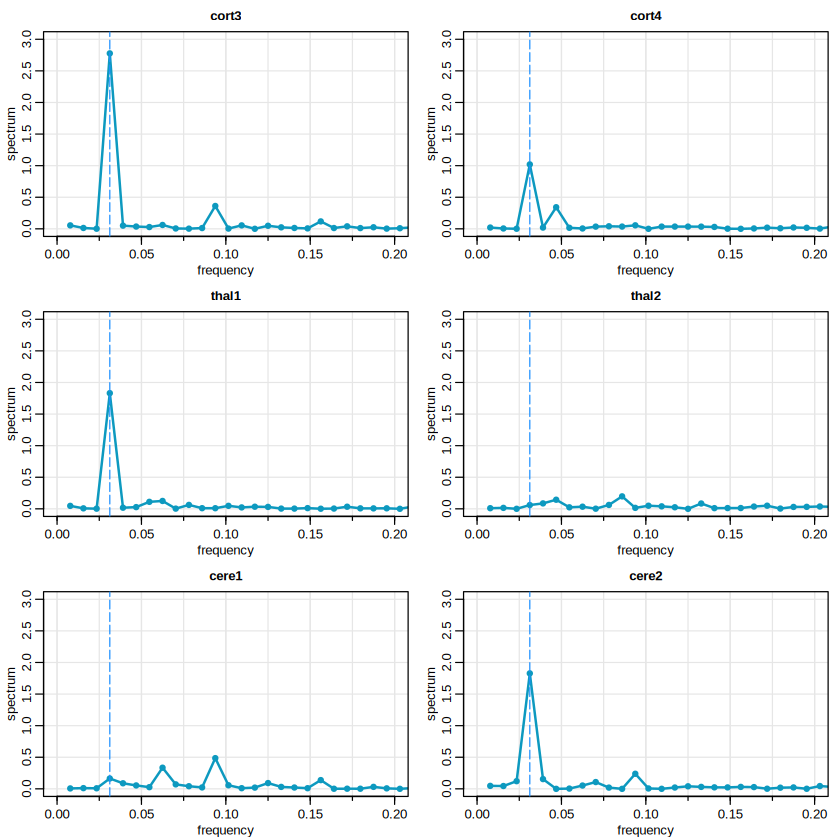

In [8]:
par(mfrow=c(3,2), mar=c(1.5,2,1,0)+1, mgp=c(1.6,.6,0))
for(i in 4:9){
  mvspec(fmri1[,i], main=colnames(fmri1)[i], ylim=c(0,3), xlim=c(0,.2),
         col=rgb(.05,.6,.75), lwd=2, type="o", pch=20)
  abline(v=1/32, col="dodgerblue", lty=5)
}
par(mfrow=c(1,1))

**Interpretation.** Each panel shows estimated spectral power (vertical axis) versus cycles per observation (horizontal axis). The dashed vertical line at $0.03125$ is the expected stimulus frequency. Look for a local peak close to that line in each brain-region signal. Spectra may differ among recordings even within the same anatomical region. A peak is descriptive evidence for periodic content; evaluating significance requires an appropriate noise model or statistical test.

## 6. Autocovariance and spectral density

The **autocovariance function (ACVF)** $\gamma(h)$ measures linear dependence at lag $h$. The **spectral density** $f(\omega)$ expresses the same second-order structure by frequency. For a stationary process with absolutely summable autocovariances,

$$\sum_{h=-\infty}^{\infty}|\gamma(h)|<\infty,$$

$$f(\omega)=\sum_{h=-\infty}^{\infty}\gamma(h)e^{-2\pi i\omega h},\qquad -\frac12\le\omega\le\frac12,$$

$$\gamma(h)=\int_{-1/2}^{1/2}e^{2\pi i\omega h}f(\omega)\,d\omega,$$

$$\operatorname{Var}(x_t)=\gamma(0)=\int_{-1/2}^{1/2}f(\omega)\,d\omega.$$

The last identity means the **area under the two-sided spectrum** equals variance. This is a variance density, not a probability density. For real-valued processes, $f(-\omega)=f(\omega)$, so the positive-frequency plot displays half of the two-sided range.

## 7. Theoretical spectra of white noise, MA(1), and AR(2)

For **white noise**, all nonzero-lag autocovariances vanish:

$$f_w(\omega)=\sigma_w^2.$$

When $\sigma_w^2=1$, the spectrum is flat at 1, showing equal variance density at every frequency.

For the **MA(1)** model $x_t=w_t+0.5w_{t-1}$,

$$f_x(\omega)=\sigma_w^2\left[1.25+\cos(2\pi\omega)\right].$$

With $\sigma_w^2=1$, the low-frequency value $f(0)=2.25$ is much greater than the Nyquist-frequency value $f(0.5)=0.25$. Positive MA coefficient $0.5$ favors slower variations.

For **AR(2)**, $x_t=x_{t-1}-0.9x_{t-2}+w_t$,

$$f_x(\omega)=\frac{\sigma_w^2}{2.81-3.8\cos(2\pi\omega)+1.8\cos(4\pi\omega)}.$$

A narrow interior peak indicates that a band of oscillation frequencies contributes especially strongly to the variance.

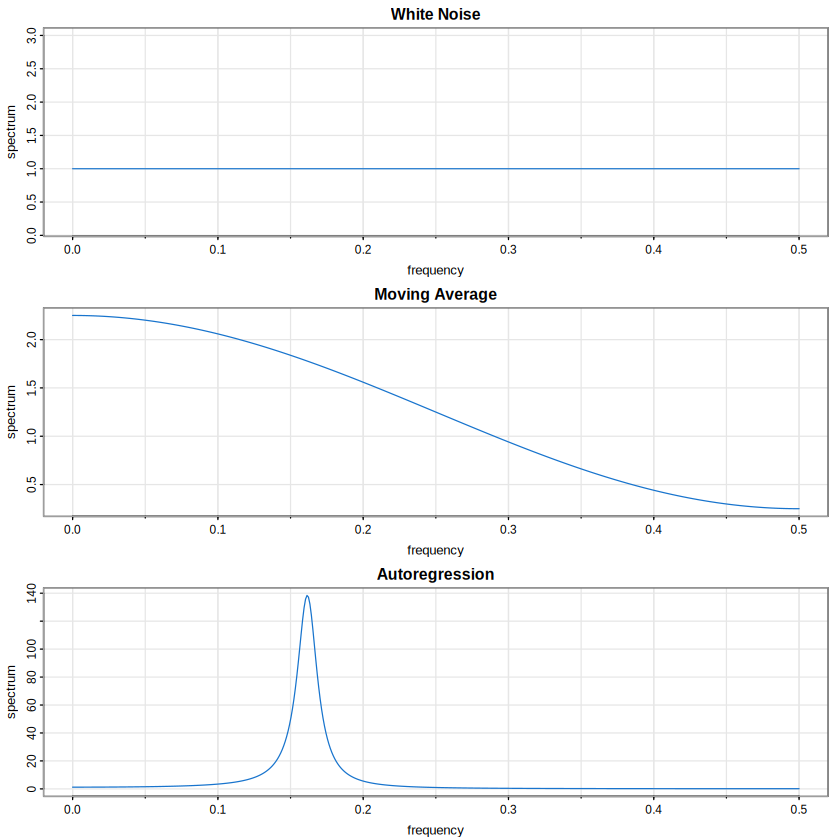

In [9]:
par(mfrow=c(3,1))
arma.spec(main="White Noise", col=4)
arma.spec(ma=.5, main="Moving Average", col=4)
arma.spec(ar=c(1,-.9), main="Autoregression", col=4)
par(mfrow=c(1,1))

In [10]:
w = seq(0,.5,length.out=2001)
fwn = rep(1,length(w))
fma = 1.25 + cos(2*pi*w)
far = 1/(2.81-3.8*cos(2*pi*w)+1.8*cos(4*pi*w))
cat("MA(1) f(0):", fma[1], "; f(0.5):", tail(fma,1), "\n")
cat("AR(2) peak frequency:", w[which.max(far)],
    "; implied period:", 1/w[which.max(far)], "observations\n")
cat("AR(2) variance from numerical integration:",
    sum((head(far,-1)+tail(far,-1))/2)*diff(w)[1]*2, "\n")

MA(1) f(0): 2.25 ; f(0.5): 0.25 
AR(2) peak frequency: 0.1615 ; implied period: 6.192 observations
AR(2) variance from numerical integration: 7.2797 


**Interpretation.** The first spectrum is flat, reflecting the absence of preferred frequencies in white noise. The MA(1) spectrum falls as frequency increases, consistent with smoother sample paths. The AR(2) spectrum peaks at an interior frequency, explaining a tendency toward repeated oscillations. The printed frequency and period report the maximum on the **numerical grid**, not an exact symbolic value. The numerical integral approximates the AR(2) process variance and provides a check on the spectrum's scale.

**Executed values:** For the MA(1), $f(0)=2.25$ and $f(0.5)=0.25$, so the low-frequency spectral density is nine times the Nyquist-frequency density. The AR(2) peak occurs at about $0.1615$ cycle/observation, equivalent to a period of $6.192$ observations. The numerical two-sided integral is $7.2797$, estimating total stationary variance under $\sigma_w^2=1$.

## 8. Linear filters and the frequency response

A **linear filter** combines neighboring or past observations with weights $a_j$:

$$y_t=\sum_{j=-\infty}^{\infty}a_jx_{t-j},\qquad \sum_j|a_j|<\infty.$$

The **impulse response coefficients** $a_j$ describe the time-domain weights. The **frequency response** describes how the filter changes an input sinusoid:

$$A_{yx}(\omega)=\sum_ja_j e^{-2\pi i\omega j}.$$

The **squared gain** $|A_{yx}(\omega)|^2$ gives the multiplicative change in spectral power at frequency $\omega$:

$$f_y(\omega)=|A_{yx}(\omega)|^2f_x(\omega).$$

A **high-pass filter** has larger gain at high frequencies; a **low-pass filter** has larger gain near frequency zero. A gain of zero completely removes that frequency; gain greater than one amplifies its power.

## 9. First differencing versus seasonal moving-average smoothing

**First difference:**

$$y_t=x_t-x_{t-1},\qquad A_{yx}(\omega)=1-e^{-2\pi i\omega},$$

$$|A_{yx}(\omega)|^2=2[1-\cos(2\pi\omega)].$$

It has gain **0** at $\omega=0$ and **4** at $\omega=0.5$, so it suppresses very slow variation and magnifies the highest-frequency power.

**Centered 12-month moving average:** weights $a_{\pm6}=1/24$ and $a_j=1/12$ for $-5\le j\le5$. The total weight is one. Its response is

$$A_{yx}(\omega)=\frac1{12}\left[1+\cos(12\pi\omega)+2\sum_{k=1}^{5}\cos(2\pi\omega k)\right].$$

This is a **low-pass** smoother. It has gain one at frequency zero and zero at the annual frequency $1/12$. By attenuating the 12-month component, slower multi-year SOI fluctuations become easier to see. The filter also suppresses parts of other frequency bands; it does not exclusively isolate El Niño.

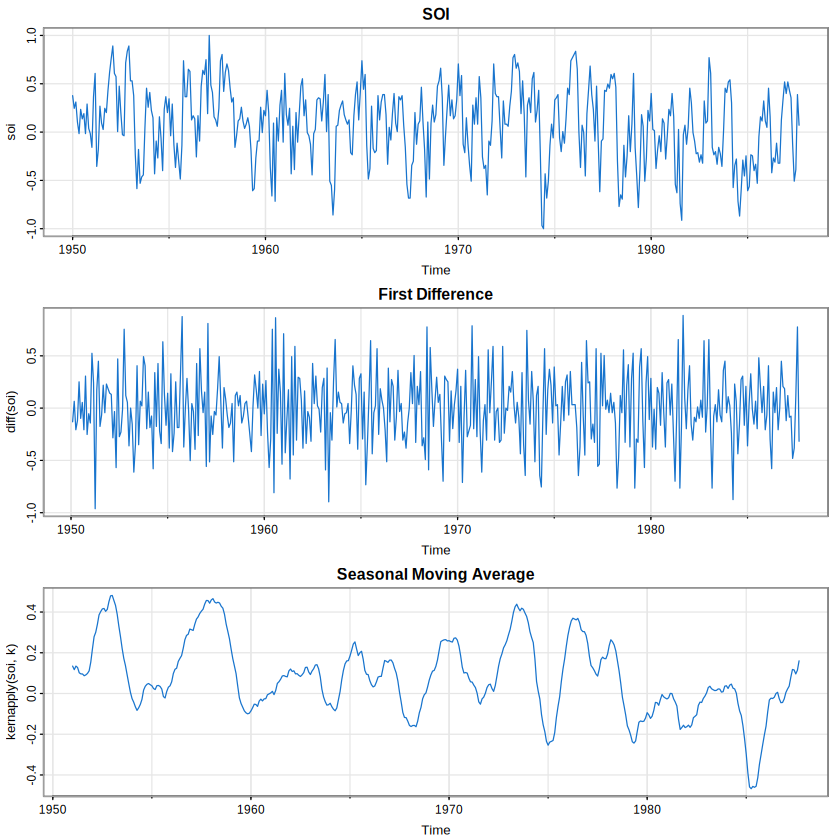

In [11]:
par(mfrow=c(3,1))
tsplot(soi, col=4, main="SOI")
tsplot(diff(soi), col=4, main="First Difference")
k = kernel("modified.daniell", 6)
tsplot(kernapply(soi, k), col=4, main="Seasonal Moving Average")
par(mfrow=c(1,1))

**Graph interpretation.** The first-differenced SOI series looks more jagged because slow changes are reduced relative to rapid changes. The centered moving average is much smoother and shows broader multi-year rises and falls. The filter creates unavailable boundary estimates, so the smoothed series can have missing endpoint values. Smoothing reveals slower structure but may conceal short-lived events.

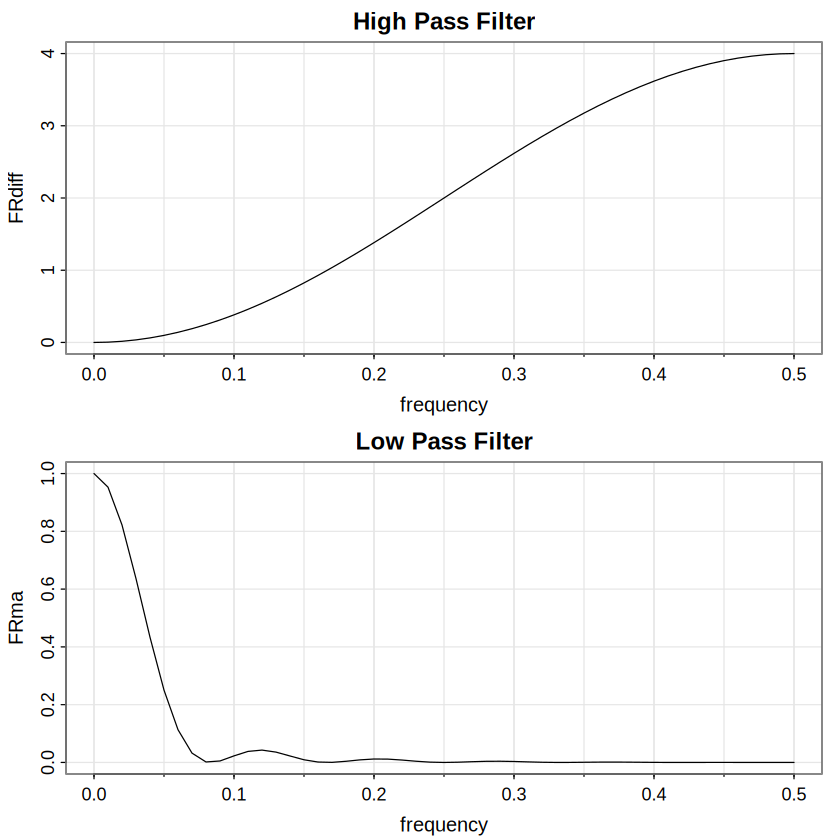

In [12]:
par(mfrow=c(2,1))
w = seq(0, .5, by=.01)
FRdiff = abs(1-exp(2i*pi*w))^2
tsplot(w, FRdiff, xlab="frequency", main="High Pass Filter")
u = cos(2*pi*w)+cos(4*pi*w)+cos(6*pi*w)+cos(8*pi*w)+cos(10*pi*w)
FRma = ((1 + cos(12*pi*w) + 2*u)/12)^2
tsplot(w, FRma, xlab="frequency", main="Low Pass Filter")
par(mfrow=c(1,1))

In [13]:
gain_at = function(freq){
  high = abs(1-exp(2i*pi*freq))^2
  v = sum(cos(2*pi*freq*(1:5)))
  low = ((1+cos(12*pi*freq)+2*v)/12)^2
  c(first_difference=high, seasonal_MA=low)
}
gain_table = t(sapply(c(0,1/48,1/12,1/2), gain_at))
rownames(gain_table) = c("zero", "48-month period", "12-month period", "Nyquist")
print(round(gain_table,6))

                first_difference seasonal_MA
zero                     0.00000     1.00000
48-month period          0.01711     0.80826
12-month period          0.26795     0.00000
Nyquist                  4.00000     0.00000


**Interpretation of computed gains.** At zero frequency the differencing gain is 0 and the moving-average gain is 1. At $1/12$ (the yearly cycle), the seasonal moving average has zero theoretical gain. At $1/48$ (an approximately four-year cycle) the smoother retains a substantial share of low-frequency power. The difference filter does the reverse: it has small gain at $1/48$ and large gain close to Nyquist. The numerical gain table confirms the frequency-domain behavior visible in the SOI plots.

**Executed gain values:** The 48-month component retains $0.80826$ of its original spectral power under the centered smoother, while the 12-month component is eliminated (gain zero). First differencing preserves only $0.01711$ of 48-month-cycle power while multiplying the 12-month component by $0.26795$; at Nyquist its gain is $4$. These numbers describe *relative spectral power*, not the actual share of total SOI variance removed.

## 10. Compare filtering formulas directly

The `kernel("modified.daniell", 6)` smoother has 13 weights: half-weights at both ends and 11 full weights between them, all divided by 12. `stats::filter()` returns a series with the original length and missing values at the six observations at each boundary, while `kernapply()` returns only the 441 interior smoothed observations. Compare the same interior time points; subtracting vectors of different lengths causes R to recycle values and produces an invalid discrepancy.

In [14]:
weights = c(.5, rep(1,11), .5)/12
manual_filter = stats::filter(soi, filter=weights, sides=2)
k = kernel("modified.daniell", 6)
package_filter = kernapply(soi, k)

# Align the common 441 interior observations before comparing.
manual_interior = as.numeric(manual_filter)[!is.na(manual_filter)]
package_interior = as.numeric(package_filter)
stopifnot(length(manual_interior) == length(package_interior))

cat("Weight total:", sum(weights), "\n")
cat("Number of aligned interior values:", length(manual_interior), "\n")
cat("Maximum absolute difference on aligned observations:",
    max(abs(manual_interior-package_interior)), "\n")

Weight total: 1 
Number of aligned interior values: 441 
Maximum absolute difference on aligned observations: 8.8818e-16 


**Interpretation.** The calculated weight total is $1$, so a constant input is preserved. The executed comparison originally returned a recycling warning and a maximum discrepancy of $0.40346$ because the full `stats::filter()` vector (including endpoint positions) was subtracted from the shorter `kernapply()` output. That number does **not** measure disagreement between the filters. The corrected code compares only the aligned 441 interior observations. The revised comparison must be run to obtain the actual maximum difference; for matching weights and numerical precision, it should be close to zero.

## Mathematical and computational checkpoints

**Theoretical behavior versus estimated evidence:** A high periodogram ordinate alone is not proof of a real physical cycle. For noisy data, peaks should be evaluated relative to a suitable background/noise model. Likewise, an apparent frequency-specific fMRI response requires inferential analysis.

**Units:** For monthly observations, $\omega=1/12$ represents cycles **per month** and a period of 12 **months**, whereas $1/48$ corresponds to 48 months. For the fMRI series, frequencies expressed per observation must be converted using the 2-second sampling interval.

**Spectral scale:** The FFT code uses the explicit $4/n$ *scaled periodogram* convention for nonzero, non-Nyquist frequencies. A package-produced spectrum may use a different scaling, so compare the peak locations before comparing heights.

**Distinguishing a filter from a model:** Differencing and moving averages are transformations of the observations. An MA($q$) stochastic model instead specifies how current and lagged random shocks generate the observations; the two uses of “moving average” should not be confused.